# Цена подержанных авто — модели (регрессия)

**Автор: Долгополова Анна**

Вход: `vehicles_clean.csv`.

План: подготовка данных → бейзлайн → несколько моделей → кросс-валидация → подбор гиперпараметров → сохранение лучшей модели.

## 1. Импорты

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

sns.set_theme(style='whitegrid')
print('Готово')

Готово


Ячейка импортирует библиотеки для расчётов, построения графиков и машинного обучения.

## 2. Загрузка очищенного датасета

Ячейка загружает файл `vehicles_clean.csv` и показывает первые строки.

In [2]:
df = pd.read_csv('vehicles_clean.csv')
print('Размер:', df.shape)
df.head()

Размер: (368049, 13)


,price,year,odometer,manufacturer,condition,cylinders,fuel,title_status,transmission,drive,size,type,paint_color
0,33590,2014,57923,gmc,good,8 cylinders,gas,clean,other,unknown,unknown,pickup,white
1,22590,2010,71229,chevrolet,good,8 cylinders,gas,clean,other,unknown,unknown,pickup,blue
2,39590,2020,19160,chevrolet,good,8 cylinders,gas,clean,other,unknown,unknown,pickup,red
3,30990,2017,41124,toyota,good,8 cylinders,gas,clean,other,unknown,unknown,pickup,red
4,15000,2013,128000,ford,excellent,6 cylinders,gas,clean,automatic,rwd,full-size,truck,black


Датасет содержит сведения о ценах, годе выпуска, пробеге и категориальных признаках авто.

## 3. Подготовка X и y

Целевая переменная — **логарифм цены** (модели работают точнее на скошенных данных). Для скорости берётся выборка 15 000 строк.

In [3]:
df = df.dropna(subset=['price'])
y = np.log1p(df['price'])
X = df.drop(columns=['price'])

if len(X) > 15000:
    idx = X.sample(15000, random_state=42).index
    X, y = X.loc[idx], y.loc[idx]

print('X:', X.shape)

X: (15000, 12)


Из полного датасета выбрана подвыборка 15 000 строк, целевая переменная переведена в логарифм.

## 4. Предобработка внутри pipeline

Кодирование категорий (One-Hot) и масштабирование числовых признаков выполняются **внутри pipeline** — это исключает утечку данных при кросс-валидации.

In [4]:
num_features = ['year', 'odometer']
cat_features = [c for c in X.columns if c not in num_features]
print('Числовые:', num_features)
print('Категориальные:', cat_features)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])

Числовые: ['year', 'odometer']
Категориальные: ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']


Числовые признаки масштабируются, категориальные кодируются One-Hot внутри единого трансформера.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (12000, 12) | Test: (3000, 12)


Данные разделены на обучающую (80%) и тестовую (20%) выборки.

## 5. Функция оценки

Метрики считаются в реальных долларах (цена возвращается из логарифма): **MAE**, **RMSE**, **R²**.

In [6]:
results = []

def evaluate(name, model):
    pred_log = model.predict(X_test)
    y_true = np.expm1(y_test)
    y_pred = np.expm1(pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name:22s} MAE={mae:8,.0f}  RMSE={rmse:8,.0f}  R2={r2:.3f}')
    results.append({'Модель': name, 'MAE': round(mae), 'RMSE': round(rmse), 'R2': round(r2, 3)})

Функция рассчитывает три метрики и накапливает результаты в общий список.

## 6. Бейзлайн — линейная регрессия

In [7]:
lin = Pipeline([('prep', preprocess), ('model', LinearRegression())])
lin.fit(X_train, y_train)
evaluate('LinearRegression', lin)

LinearRegression       MAE=   4,925  RMSE=   7,808  R2=0.694


Линейная регрессия служит базовой точкой отсчёта для сравнения с более сложными моделями.

## 7. Случайный лес

In [8]:
rf = Pipeline([('prep', preprocess),
               ('model', RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42))])
rf.fit(X_train, y_train)
evaluate('RandomForest', rf)

RandomForest           MAE=   3,948  RMSE=   6,745  R2=0.772


Случайный лес показывает существенно более высокую точность по сравнению с линейной регрессией.

## 8. Градиентный бустинг

In [9]:
gb = Pipeline([('prep', preprocess),
               ('model', GradientBoostingRegressor(n_estimators=50, random_state=42))])
gb.fit(X_train, y_train)
evaluate('GradientBoosting', gb)

GradientBoosting       MAE=   5,157  RMSE=   8,183  R2=0.664


Градиентный бустинг добавляет третье сравнительное измерение среди ансамблевых моделей.

## 9. Сравнение моделей

In [10]:
comparison = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
comparison

,Модель,MAE,RMSE,R2
0,RandomForest,3948,6745,0.772
1,LinearRegression,4925,7808,0.694
2,GradientBoosting,5157,8183,0.664


Таблица сводит метрики всех обученных моделей, отсортированных по R².

## 10. Кросс-валидация

Проверка устойчивости случайного леса по 3 фолдам (метрика R²).

In [11]:
cv_scores = cross_val_score(rf, X_train, y_train, cv=3, scoring='r2', n_jobs=-1)
print('R² по фолдам:', np.round(cv_scores, 3))
print('Среднее R²:', round(cv_scores.mean(), 3))

R² по фолдам: [0.684 0.661 0.73 ]
Среднее R²: 0.692


Значения R² на разных фолдах близки друг к другу — результат устойчив.

## 11. Подбор гиперпараметров

`RandomizedSearchCV` для случайного леса.

In [12]:
param_dist = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 2, 5],
}
search = RandomizedSearchCV(
    rf, param_dist, n_iter=3, cv=2, scoring='r2',
    n_jobs=-1, random_state=42, verbose=1
)
search.fit(X_train, y_train)
print('Лучшие параметры:', search.best_params_)
print('Лучший CV R²:', round(search.best_score_, 3))

Fitting 2 folds for each of 3 candidates, totalling 6 fits


Лучшие параметры: {'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Лучший CV R²: 0.685


Подобранная комбинация гиперпараметров максимизирует средний R² на кросс-валидации.

In [13]:
best_model = search.best_estimator_
evaluate('RandomForest (tuned)', best_model)
pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)

RandomForest (tuned)   MAE=   3,904  RMSE=   6,677  R2=0.776


,Модель,MAE,RMSE,R2
0,RandomForest (tuned),3904,6677,0.776
1,RandomForest,3948,6745,0.772
2,LinearRegression,4925,7808,0.694
3,GradientBoosting,5157,8183,0.664


После настройки гиперпараметров модель повторно оценивается на тестовой выборке.

## 12. Важность признаков

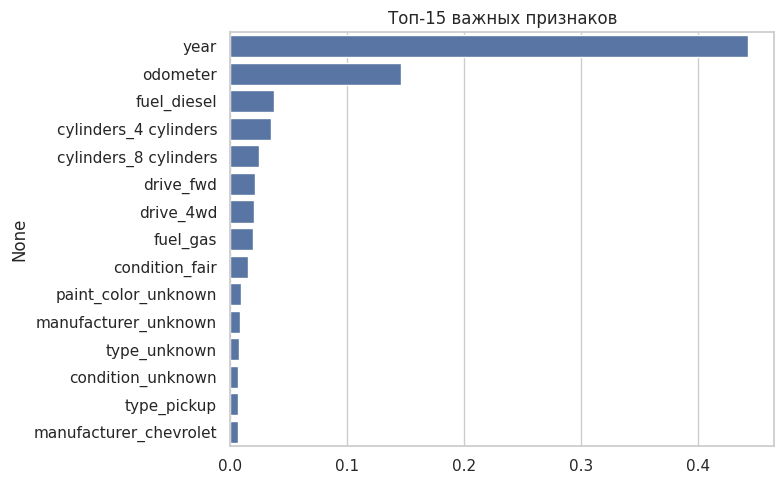

In [14]:
ohe = best_model.named_steps['prep'].named_transformers_['cat']
feat_names = num_features + list(ohe.get_feature_names_out(cat_features))
importances = best_model.named_steps['model'].feature_importances_
fi = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
sns.barplot(x=fi.values, y=fi.index)
plt.title('Топ-15 важных признаков')
plt.tight_layout()
plt.show()

Наибольший вклад в предсказание цены вносят год выпуска, пробег и отдельные категории марок/типов.

## 13. Сохранение модели

Ячейка сохраняет весь pipeline (предобработка + модель) одним файлом.

In [15]:
joblib.dump(best_model, 'car_price_model.pkl')
print('Модель сохранена: car_price_model.pkl')
print('Признаки на вход:', list(X.columns))

Модель сохранена: car_price_model.pkl
Признаки на вход: ['year', 'odometer', 'manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']


Итоговый pipeline сериализован в `car_price_model.pkl` вместе с именами входных признаков.

## 14. Выводы

Сравнение трёх моделей на тестовой выборке дало следующие результаты:

| Модель                | MAE   | RMSE | R²    |
|-----------------------|-------|------|-------|
| LinearRegression      | 4 925 | 7 808 | 0.694 |
| RandomForest          | 3 948 | 6 745 | 0.772 |
| GradientBoosting      | 5 157 | 8 183 | 0.664 |
| RandomForest (tuned)  | 3 904 | 6 677 | **0.776** |

Лучший результат показал **RandomForest (tuned)** с R² = 0.776 и MAE ≈ 3 900 $. Подбор гиперпараметров (`RandomizedSearchCV`, лучшие параметры: `n_estimators=100`, `max_depth=None`, `min_samples_leaf=1`) дал небольшой прирост по сравнению с базовым случайным лесом.

Кросс-валидация (3 фолда) подтвердила устойчивость модели: среднее R² ≈ 0.692, разброс между фолдами небольшой.

Наиболее важные признаки — `year`, `odometer`, марка и тип авто. Меньший вклад вносят цвет и тип привода.

Финальная модель сохранена в `car_price_model.pkl` и готова к использованию для предсказания цены подержанного авто по входным признакам.